# Week 2 — Price waterfall & aggregation

**AXIOM Pricing Module · Track A**

The waterfall (D2) built on one line-grain fact table, rolled up to every
dimension the deliverable requires, then handed across the Track B contract.

Two things this notebook is for: seeing that the arithmetic holds, and seeing
what the numbers actually say about the business.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt

from pricing.engine import aggregation as agg
from pricing.engine import pipeline, waterfall as wf
from pricing.graph import get_source, validate

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

src = get_source()
print(validate(src))

Snapshot validation: 0 blocking, 4 warnings
  [WARNING] list price coverage: 1 product(s) have no list_price; 60 transactions cannot report price realisation (60 affected)
  [WARNING] cost coverage: 2 product(s) have no unit_cost; 113 transactions cannot report pocket margin (113 affected)
  [WARNING] currency: 5 currencies (AED, EUR, GBP, PLN, TND) and no FX rate in the graph -- aggregates spanning currencies cannot be published; include `currency` in the grain (5 affected)
  [WARNING] discount amounts: discount applied with unknown amount -- leakage understated on those deals (11 affected)


The snapshot is degraded but structurally sound, so the engine runs. Warnings
are carried through into the confidence score on every published record — they
are not swept aside.

Note the currency warning. It is the most consequential finding of Week 2; §4 below.

## 1. The fact table

One row per (transaction, product). Every waterfall step, every dimension, and the certification flags — everything else in this notebook is a groupby over it.

In [2]:
w = wf.compute(src)
print(f"{len(w.facts):,} lines  x  {w.facts.shape[1]} columns")
w.facts[["transaction_id","product_id","segment","currency","list_value","gross_value",
         "on_invoice_discount","off_invoice_leakage","pocket_price","cogs",
         "pocket_margin","certified"]].head()

1,408 lines  x  45 columns


,transaction_id,product_id,segment,currency,list_value,gross_value,on_invoice_discount,off_invoice_leakage,pocket_price,cogs,pocket_margin,certified
0,TRX-00001,PRD-016,Enterprise,TND,"42,820.18","37,904.62","5,399.12","1,750.85","30,754.65","22,519.38","8,235.27",False
1,TRX-00001,PRD-018,Enterprise,TND,"25,086.45","21,535.40","3,067.49",994.74,"17,473.17",NaN,NaN,False
2,TRX-00002,PRD-017,Enterprise,PLN,"91,518.40","78,714.80","12,780.96","8,500.93","57,432.91","56,469.20",963.71,True
3,TRX-00002,PRD-023,Enterprise,PLN,"9,975.71","8,601.69","1,396.66",928.95,"6,276.08","6,440.32",-164.24,True
4,TRX-00003,PRD-002,Public Sector,EUR,"45,710.09","44,214.85","2,984.90",0.00,"41,229.95","23,309.04","17,920.91",True


### The waterfall

In [3]:
print(w.summary())

  Coverage: 530/700 transactions fully decomposable (75.7%). Certified only below.

  List value                   31,108,764.18   (100.0% of list)
  - negotiated off-list         3,688,235.18   ( 11.9% of list)
  = Gross (invoiced) value     27,420,529.00   ( 88.1% of list)
  - on-invoice discounts        3,669,609.59   ( 11.8% of list)
  = Invoice price              23,750,919.41   ( 76.3% of list)
  - off-invoice leakage         1,117,996.07   (  3.6% of list)
  = Pocket price               22,632,923.34   ( 72.8% of list)
  - COGS                       18,513,092.48   ( 59.5% of list)
  = Pocket margin               4,119,830.86   ( 13.2% of list)
  Pocket margin %                      18.20%
  Price realisation                    72.75%   (pocket / list)


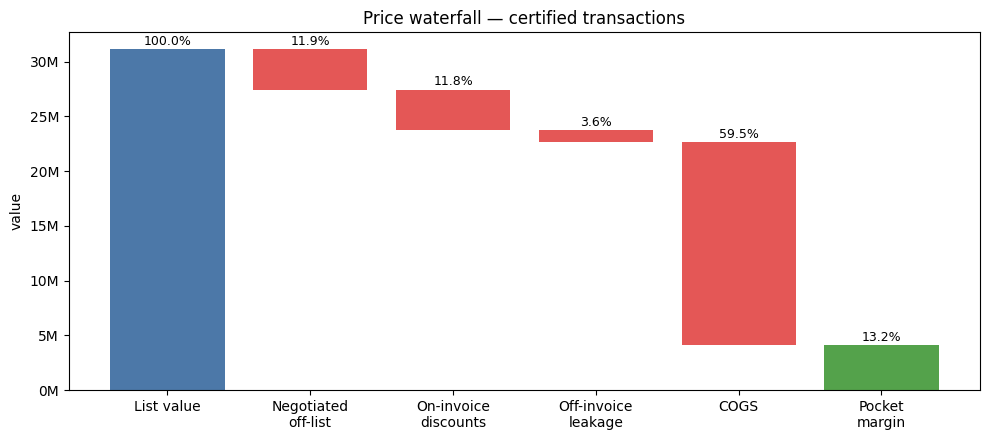

In [4]:
t = w.totals
steps  = ["list_value","negotiated_off_list","on_invoice_discount","off_invoice_leakage","cogs","pocket_margin"]
labels = ["List value","Negotiated\noff-list","On-invoice\ndiscounts","Off-invoice\nleakage","COGS","Pocket\nmargin"]

fig, ax = plt.subplots(figsize=(10, 4.5))
running = 0
for i,(lab,key) in enumerate(zip(labels, steps)):
    v = t[key]
    if i == 0:
        ax.bar(lab, v, color="#4C78A8"); running = v
    elif i == len(steps)-1:
        ax.bar(lab, v, color="#54A24B")
    else:
        running -= v
        ax.bar(lab, v, bottom=running, color="#E45756")
    ax.text(i, (running + v if i not in (0,len(steps)-1) else v) + 4e5, f"{100*v/t['list_value']:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("value"); ax.set_title("Price waterfall — certified transactions")
ax.yaxis.set_major_formatter(lambda x,p: f"{x/1e6:.0f}M")
plt.tight_layout(); plt.show()

27% of list value never reaches the pocket. Two-thirds of that is on-invoice
discounting plus the negotiated gap below list; the rest is off-invoice leakage —
the part that never shows up on an invoice at all.

## 2. Data quality — what we cannot compute, and why

In [5]:
w.flags

,flag,n_lines,n_transactions,consequence
0,product missing list_price,60,60,list value & price realisation UNAVAILABLE
1,product missing unit_cost,116,113,COGS & pocket margin UNAVAILABLE
2,discount applied with unknown amount,15,11,leakage understated; not certified
3,line priced above list,0,0,negative discount -- check list price maintenance
4,negative pocket margin,117,99,"selling below cost -- a real finding, not an e..."


Note the last row. 99 transactions carry **negative** pocket margin: sold below
cost. That is not a data error, it is a finding, and it is flagged as one.

## 3. Aggregation

Every dimension D2 requires. Each is a groupby over the same fact table, so they cannot disagree with each other.

In [6]:
for dim in wf.DIMENSIONS:
    rec = agg.reconciles_with_total(w, dim)
    print(f"{dim:<14} reconciles: {bool(rec['ok'].all())}   max |diff| = {rec['diff'].abs().max():.6f}")

customer_id    reconciles: True   max |diff| = 0.000000


product_id     reconciles: True   max |diff| = 0.000000
segment        reconciles: True   max |diff| = 0.000000
channel_id     reconciles: True   max |diff| = 0.000000
region_id      reconciles: True   max |diff| = 0.000000
period         reconciles: True   max |diff| = 0.000000


Exact to the cent on all six. This check runs on every pipeline execution, not
just here — it is how a join fanout gets caught before it reaches a report.

In [7]:
seg = agg.aggregate(w, "segment")
seg[["segment","n_transactions","n_transactions_certified","coverage_pct","n_currencies",
     "list_value","pocket_price","pocket_margin_pct","price_realisation_pct",
     "off_invoice_leakage_pct","status"]]

,segment,n_transactions,n_transactions_certified,coverage_pct,n_currencies,list_value,pocket_price,pocket_margin_pct,price_realisation_pct,off_invoice_leakage_pct,status
0,Enterprise,172,134,77.91,5,"16,007,301.85","10,336,046.13",7.04,64.57,5.74,complete
1,Mid-Market,181,132,72.93,5,"5,360,206.35","4,132,596.74",24.16,77.10,3.70,complete
2,Public Sector,161,126,78.26,5,"8,277,876.04","6,885,094.33",28.79,83.17,1.74,complete
3,SMB,186,138,74.19,5,"1,463,379.94","1,279,186.14",32.21,87.41,2.01,complete


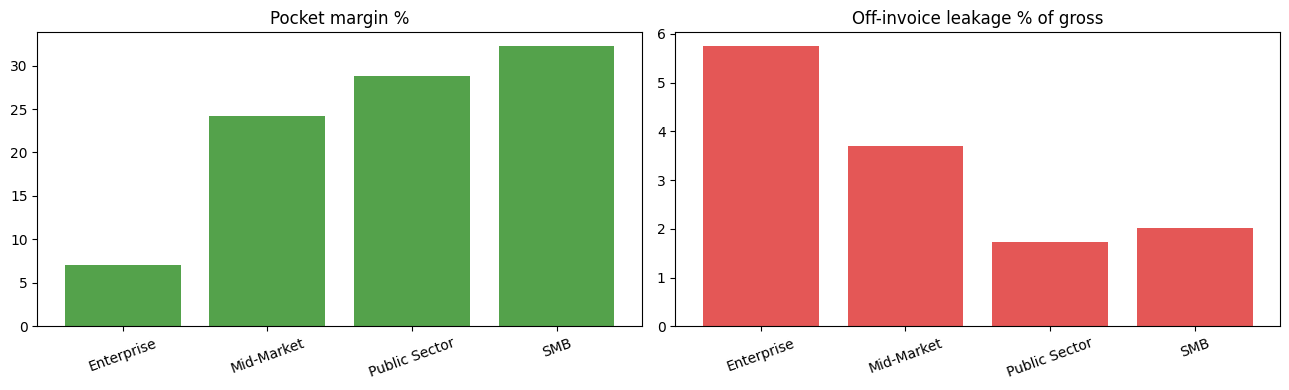

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(seg.segment, seg.pocket_margin_pct, color="#54A24B")
axes[0].set_title("Pocket margin %"); axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(seg.segment, seg.off_invoice_leakage_pct, color="#E45756")
axes[1].set_title("Off-invoice leakage % of gross"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**The headline finding.** Margin runs the wrong way down the customer size
ladder: Enterprise keeps ~7% while SMB keeps ~32%, and Enterprise simultaneously
carries the *highest* off-invoice leakage. The biggest accounts negotiate the
biggest concessions, and most of those concessions are the invisible kind.

(These particular figures span currencies — see §4 — so read the shape, not the
absolute values.)

### Where is margin leaking?

In [9]:
agg.leakage_ranking(w, "customer", 10)

,customer_id,customer_name,list_value,off_invoice_leakage,pocket_price,n_transactions_certified,pocket_margin_pct,off_invoice_leakage_pct,total_leakage_pct,leaked_value
0,CUS-029,Orbis Systems 29,"2,332,395.03","139,772.95","1,459,485.98",20,4.32,7.11,37.43,"872,909.05"
1,CUS-017,Vega Systems 17,"2,024,251.26","124,206.18","1,333,145.72",16,7.45,7.13,34.14,"691,105.54"
2,CUS-013,Orbis Systems 13,"1,955,132.72","51,373.44","1,311,237.37",13,13.07,3.10,32.93,"643,895.35"
3,CUS-033,Orbis Group 33,"1,671,924.09","91,847.68","1,056,385.13",15,4.54,6.51,36.82,"615,538.96"
4,CUS-021,Delta Group 21,"1,752,531.25","85,840.03","1,145,415.95",16,6.00,5.76,34.64,"607,115.30"
5,CUS-009,Vega Works 9,"1,523,295.57","64,959.45","954,062.22",16,-1.59,5.11,37.37,"569,233.35"
6,CUS-037,Delta Technik 37,"1,402,951.79","43,577.32","930,093.39",10,12.63,3.68,33.70,"472,858.40"
7,CUS-025,Astra Systems 25,"1,199,537.41","70,550.48","742,947.75",9,7.96,7.01,38.06,"456,589.66"
8,CUS-001,Vega Group 1,"1,226,957.96","74,447.75","807,402.67",13,9.64,7.06,34.19,"419,555.29"
9,CUS-005,Vega Works 5,"918,324.77","31,861.10","595,869.95",6,6.30,4.12,35.11,"322,454.82"


In [10]:
agg.leakage_ranking(w, "product", 10)

,product_id,product_name,list_value,off_invoice_leakage,pocket_price,n_transactions_certified,pocket_margin_pct,off_invoice_leakage_pct,total_leakage_pct,leaked_value
0,PRD-009,Maintenance I108,"2,911,493.76","95,882.22","2,113,917.35",58,25.82,3.74,27.39,"797,576.41"
1,PRD-005,Proximity E104,"2,668,191.78","100,370.85","1,877,568.12",51,8.31,4.33,29.63,"790,623.66"
2,PRD-006,Vision F105,"2,585,309.32","90,037.60","1,823,208.60",47,5.04,4.02,29.48,"762,100.72"
3,PRD-022,Servo Drives V121,"2,788,836.12","93,037.00","2,113,086.45",43,12.19,3.73,24.23,"675,749.67"
4,PRD-017,UPS Q116,"2,201,017.52","59,135.62","1,592,710.36",39,14.73,3.09,27.64,"608,307.16"
5,PRD-002,Servo Drives B101,"2,255,556.51","68,643.05","1,698,618.20",57,32.29,3.40,24.69,"556,938.31"
6,PRD-004,HMI D103,"1,963,298.60","68,890.05","1,437,547.11",42,34.33,3.98,26.78,"525,751.49"
7,PRD-016,Vision P115,"1,946,671.26","79,558.71","1,439,870.08",50,28.90,4.57,26.03,"506,801.18"
8,PRD-024,HMI X123,"1,602,153.28","68,641.19","1,097,720.75",39,14.90,4.97,31.48,"504,432.53"
9,PRD-014,HMI N113,"1,810,414.41","67,766.33","1,353,350.04",47,26.15,4.20,25.25,"457,064.37"


### Over time

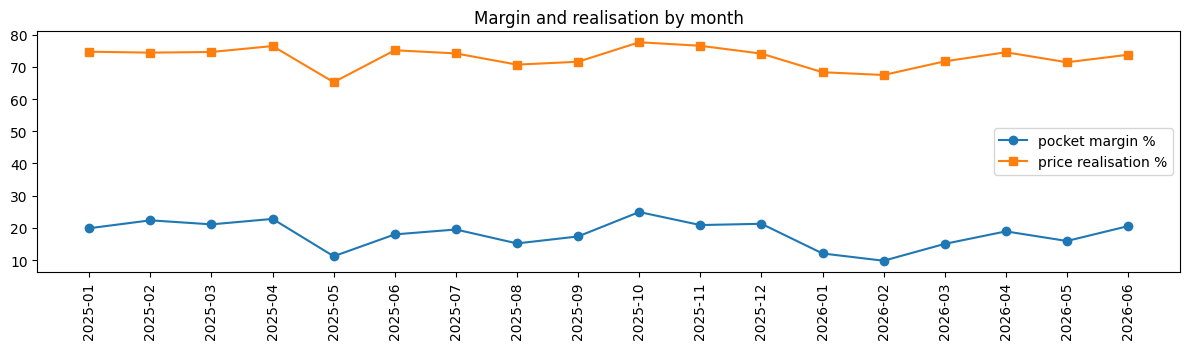

In [11]:
per = agg.aggregate(w, "period")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(per.period, per.pocket_margin_pct, marker="o", label="pocket margin %")
ax.plot(per.period, per.price_realisation_pct, marker="s", label="price realisation %")
ax.legend(); ax.set_title("Margin and realisation by month"); plt.xticks(rotation=90)
plt.tight_layout(); plt.show()

## 4. The currency problem

The graph carries a currency per region and **no FX rate anywhere**. So any
aggregate that spans regions — including every segment number above — has been
summing AED + EUR + GBP + PLN + TND as if they were one unit.

In [12]:
w.facts.groupby("currency").agg(n_lines=("gross_value","size"), gross=("gross_value","sum"))

,n_lines,gross
currency,,
AED,339,"9,194,782.93"
EUR,384,"10,291,385.26"
GBP,261,"7,942,665.47"
PLN,176,"4,663,144.73"
TND,248,"6,343,881.01"


In [13]:
from pricing.engine import result as rb
from pricing.contracts import schema as C

mixed = rb.build(w, grains=("segment",), min_transactions=3)
rec = mixed.waterfalls[0]
print("grain 'segment' (spans currencies):")
print(f"  status       {rec.status.value}")
print(f"  pocket_price {rec.pocket_price.amount}   currency={rec.pocket_price.currency}")
print(f"  reason       {rec.pocket_price.note}")
print(f"  confidence   {rec.confidence.band.value}")

grain 'segment' (spans currencies):
  status       abstained
  pocket_price None   currency=MIXED
  reason       aggregate spans 5 currencies (AED,EUR,GBP,PLN,TND) and the graph carries no FX rate; summing them would produce a number with no unit
  confidence   none


The engine refuses to publish it — amounts, ratios and confidence all suppressed,
with the reason stated in the payload rather than in a comment somewhere.

The fix at the call site is to put currency in the grain.

In [14]:
byseg_ccy = agg.aggregate(w, ["segment", "currency"])
byseg_ccy[["segment","currency","n_transactions_certified","coverage_pct",
           "pocket_price","pocket_margin_pct","price_realisation_pct"]].head(10)

,segment,currency,n_transactions_certified,coverage_pct,pocket_price,pocket_margin_pct,price_realisation_pct
0,Enterprise,AED,29,78.38,"2,140,548.39",8.27,65.84
1,Enterprise,EUR,42,80.77,"3,009,418.15",2.84,63.04
2,Enterprise,GBP,38,74.51,"3,297,715.89",10.22,65.56
3,Enterprise,PLN,9,81.82,"742,947.75",7.96,61.94
4,Enterprise,TND,16,76.19,"1,145,415.95",6.00,65.36
5,Mid-Market,AED,36,65.45,"1,017,309.44",25.42,76.29
6,Mid-Market,EUR,24,72.73,"778,595.94",24.22,76.00
7,Mid-Market,GBP,14,70.00,"410,589.69",25.83,79.64
8,Mid-Market,PLN,18,81.82,"428,991.99",18.71,74.50
9,Mid-Market,TND,40,78.43,"1,497,109.68",24.38,78.35


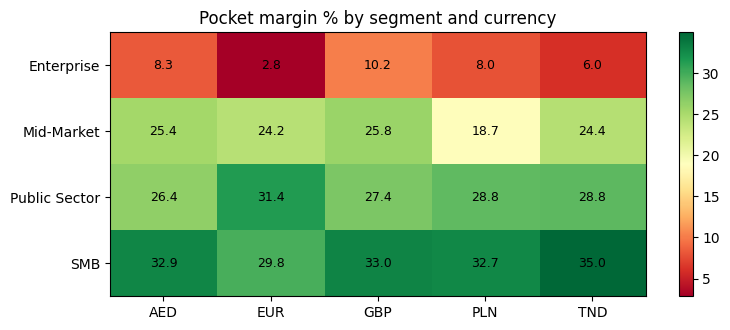

In [15]:
piv = byseg_ccy.pivot(index="segment", columns="currency", values="pocket_margin_pct")
fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(piv.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns)
ax.set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9)
ax.set_title("Pocket margin % by segment and currency")
plt.colorbar(im); plt.tight_layout(); plt.show()

The Enterprise-is-worst pattern holds **within** every currency, so it is a real
commercial signal and not an artefact of the currency mixing.

## 5. The handover to Track B

The full pipeline: validate, compute, aggregate, translate to the contract, track the run.

In [16]:
run = pipeline.run(src, track=False)
print("validation ok      :", run.validation.ok)
print("all reconcile      :", bool(run.reconciliation['ok'].all()))
print("contract violations:", run.contract_violations or "none")
print("records emitted    :", len(run.result.waterfalls))

validation ok      : True
all reconcile      : True
contract violations: none
records emitted    : 20


In [17]:
r = run.result.waterfalls[0]
print("grain      :", r.grain)
print("key        :", r.key)
print("pocket     :", f"{r.pocket_price.amount:,.2f} {r.pocket_price.currency}")
print("margin %   :", r.pocket_margin_pct)
print("status     :", r.status.value)
print("confidence :", r.confidence.band.value, r.confidence.score)
for why in r.confidence.reasons:
    print("   -", why)
print("evidence   :", r.evidence.count(), "transactions, e.g.", r.evidence.transaction_ids[:3])

grain      : segmentxcurrency
key        : {'segment': 'Enterprise', 'currency': 'AED'}
pocket     : 2,140,548.39 AED
margin %   : 8.27
status     : partial
confidence : medium 0.7838
   - another line in this transaction is incomplete
   - discount applied with unknown amount
   - product has no list_price
   - product has no unit_cost
   - 8 of 37 transactions not fully decomposable
evidence   : 29 transactions, e.g. ('TRX-00014', 'TRX-00035', 'TRX-00081')


That last block is the whole point of the contract. Mohamed receives a number, a
unit, a status, a confidence with stated reasons, and the exact transaction IDs
the number came from — enough to write a cited narrative without ever
recalculating anything.

In [18]:
print(run.result.to_json()[:1400], "...")

{
  "provenance": {
    "snapshot_backend": "csv",
    "snapshot_location": "/sessions/confident-brave-curie/mnt/data/axiom-pricing-module/data/snapshot_synthetic_v1",
    "snapshot_hash": "6af98ff70daf16a190620736a6b51ef4dd25cd0c2ef65887448b348d15e33e61",
    "contract_version": "0.2.0-draft",
    "engine_version": "0.2.0",
    "computed_at": "2026-08-05T13:47:01.292381+00:00",
    "mlflow_run_id": null
  },
  "waterfalls": [
    {
      "grain": "segmentxcurrency",
      "key": {
        "segment": "Enterprise",
        "currency": "AED"
      },
      "list_value": {
        "amount": 3251209.22,
        "currency": "AED",
        "status": "complete",
        "note": null
      },
      "negotiated_off_list": {
        "amount": 456311.38,
        "currency": "AED",
        "status": "complete",
        "note": null
      },
      "gross_value": {
        "amount": 2794897.84,
        "currency": "AED",
        "status": "complete",
        "note": null
      },
      "on_invoice_d

## 6. Into Weeks 3–4

- **D3**: margin distributions, IQR outliers, leakage KPIs, and the 0–100
  Pricing Data Readiness Score that replaces the placeholder confidence.
- **Currency** is the question to settle first — it changes every aggregate.
- **The 99 negative-margin deals** are the first thing to put in front of someone
  commercial: deliberate loss-leaders, or uncontrolled discounting?